# Vinculum 06 · Backtests with costs (unimatrix-zero)

`unimatrix-zero` simulates portfolios built from `neural-processor` signals on vinculum's
point-in-time universes:

- **returns**: daily total returns by security, linked across holding-company reorganizations,
  with a delisting return when a stock stops trading (its last close, or -30% after a collapse);
- **execution**: weights formed at a month-end close trade at the next day's close (`lag=1`),
  then drift with prices until the next rebalance;
- **costs**: half-spread modelled from dollar volume, 1 bp commission, 25 bp a year to borrow
  (300 bp for hard-to-borrow names) and, given an AUM, square-root market impact.

1. signals and a first backtest
2. what each assumption changes
3. value, quality, momentum and the combination
4. long and short legs, exposures
5. capacity
6. long-only
7. caveats

In [1]:
import matplotlib.pyplot as plt
import polars as pl
from massive_subspace_stream import Store
from neural_processor import Processor, composite
from subspace_probe import style, timed
from unimatrix_zero import NO_COSTS, CostModel, Engine, quantile_weights, top_n_weights
from vinculum import Vinculum

style()
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_cols(16)
v, massive = Vinculum(), Store()
p, eng = Processor(vinculum=v, store=massive), Engine(vinculum=v, store=massive)
START, TOP = "2012-01-01", 1000
VALUE = ["earnings_yield", "book_to_market", "fcf_yield", "ebitda_to_ev"]
QUALITY = ["roe", "gross_profitability", "cash_roa", "accruals"]
with timed("signal panel"):
    sig = p.panel([*VALUE, *QUALITY, "momentum_12_1"], start=START, top=TOP)
sig = composite(sig, VALUE, name="value", min_signals=2)
sig = composite(sig, QUALITY, name="quality", min_signals=2)
sig = composite(sig, ["momentum_12_1"], name="momentum")
sig = composite(sig, {"value": 1, "quality": 1, "momentum": 1}, name="combined", min_signals=2)
print(f"{sig.height:,} rows, {sig['date'].n_unique()} month ends")


def show(bt, label):
    s = bt.summary().filter(pl.col("series") == "net").row(0, named=True)
    g = bt.summary().filter(pl.col("series") == "gross").row(0, named=True)
    return {"portfolio": label, "gross_return": g["ann_return"], "net_return": s["ann_return"],
            "net_vol": s["ann_vol"], "gross_sharpe": g["sharpe"], "net_sharpe": s["sharpe"], "t_stat": s["t_stat"],
            "max_drawdown": s["max_drawdown"], "turnover_per_year": s["turnover_per_year"], "cost_drag": s["cost_drag"],
            "beta": s.get("beta")}


def table(rows):
    return pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(3))

signal panel: 15.87 s
178,000 rows, 178 month ends


## 1 · A first backtest

Long the top fifth of the top 1,000 on the combined score, short the bottom fifth, equal
weights, monthly, default costs, trading the day after the signal.

In [2]:
w = quantile_weights(sig, "combined", q=0.2)
with timed("backtest"):
    bt = eng.run(w)
bt.summary().with_columns(pl.col(pl.Float64).round(3))

backtest: 22.37 s


series,ann_return,ann_vol,sharpe,t_stat,max_drawdown,start,end,years,turnover_per_rebalance,turnover_per_year,cost_drag,avg_gross_exposure,avg_net_exposure,beta,alpha
str,f64,f64,f64,f64,f64,date,date,f64,f64,f64,f64,f64,f64,f64,f64
"""net""",0.055,0.098,0.591,2.269,-0.174,2012-02-01,2026-10-30,14.72,0.932,11.203,0.009,2.005,0.003,-0.019,0.061
"""gross""",0.064,0.098,0.68,2.61,-0.172,null,null,null,null,null,null,null,null,null,null
"""long leg""",0.143,0.182,0.828,3.178,-0.372,null,null,null,null,null,null,null,null,null,null
"""short leg""",-0.098,0.194,-0.432,-1.658,-0.818,null,null,null,null,null,null,null,null,null,null


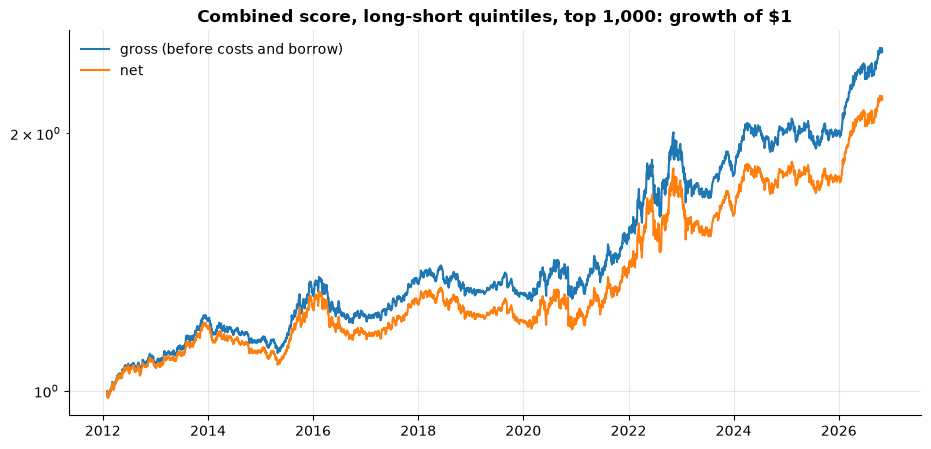

year,gross,net,long,short,turnover,cost,borrow
i32,f64,f64,f64,f64,f64,f64,f64
2012,0.081,0.069,0.101,-0.037,11.703,0.009,0.002
2013,0.118,0.107,0.42,-0.226,10.888,0.007,0.003
2014,-0.055,-0.063,0.07,-0.132,10.133,0.006,0.003
2015,0.137,0.127,-0.016,0.129,10.959,0.006,0.002
2016,-0.057,-0.066,0.092,-0.158,11.863,0.007,0.003
2017,0.09,0.081,0.25,-0.134,10.931,0.006,0.002
2018,-0.012,-0.02,-0.103,0.074,10.206,0.005,0.003
2019,-0.018,-0.027,0.287,-0.251,11.811,0.007,0.003
2020,0.006,-0.004,0.23,-0.269,12.832,0.007,0.003


In [3]:
d = bt.daily.with_columns((1 + pl.col("gross")).cum_prod().alias("nav_gross"))
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(d["date"], d["nav_gross"], label="gross (before costs and borrow)")
ax.plot(d["date"], d["nav"], label="net")
ax.set_yscale("log")
ax.set_title("Combined score, long-short quintiles, top 1,000: growth of $1")
ax.legend()
plt.show()
bt.by_year().with_columns(pl.col(pl.Float64).round(3))

The long leg earns most of the return; the short leg loses money in most years, as the shorted
stocks rise with the market, but less than the long leg makes. Turnover is about 11 times a
year (two-sided, as a multiple of capital), which costs under one percentage point a year
including borrow: the top 1,000 trade at half-spreads of a few basis points.

## 2 · What each assumption changes

The same weights, one assumption at a time:

In [4]:
variants = [
    ("no costs, trade at the signal close", dict(costs=NO_COSTS, lag=0)),
    ("no costs, next-day close", dict(costs=NO_COSTS, lag=1)),
    ("default costs, next-day close", dict()),
    ("costs from the noisy spread estimate", dict(costs=CostModel(spread="estimate"))),
    ("delisting at last close only", dict(delisting="last")),
    ("no names under $5", dict(min_price=5.0)),
]
rows = []
with timed(f"{len(variants)} backtests"):
    for label, kw in variants:
        rows.append(show(eng.run(w, **kw), label))
    rows.append(show(eng.run(quantile_weights(sig, "combined", q=0.2, sector_neutral=True)), "sector neutral"))
    rows.append(show(eng.run(quantile_weights(sig, "combined", q=0.2, weighting="cap")), "cap weighted"))
table(rows)

6 backtests: 189.65 s


portfolio,gross_return,net_return,net_vol,gross_sharpe,net_sharpe,t_stat,max_drawdown,turnover_per_year,cost_drag,beta
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""no costs, trade at the signal …",0.069,0.069,0.098,0.728,0.728,2.792,-0.167,11.222,0.0,-0.018
"""no costs, next-day close""",0.064,0.064,0.098,0.68,0.68,2.61,-0.172,11.202,0.0,-0.018
"""default costs, next-day close""",0.064,0.055,0.098,0.68,0.591,2.269,-0.174,11.203,0.009,-0.019
"""costs from the noisy spread es…",0.064,0.033,0.099,0.68,0.381,1.462,-0.19,11.203,0.031,-0.017
"""delisting at last close only""",0.064,0.055,0.098,0.68,0.591,2.267,-0.174,11.203,0.009,-0.019
"""no names under $5""",0.061,0.052,0.099,0.65,0.563,2.16,-0.175,11.257,0.009,-0.02
"""sector neutral""",0.049,0.039,0.08,0.637,0.524,2.011,-0.156,11.648,0.009,-0.013
"""cap weighted""",0.074,0.067,0.121,0.653,0.599,2.297,-0.231,10.459,0.007,0.044


- **Execution lag**: trading a day after the signal instead of at its own close costs about
  half a point a year (Sharpe 0.73 to 0.68): month-end signals keep most of their value, fast
  ones such as short-term reversal would not.
- **Spread model**: the Abdi-Ranaldo estimate from daily highs and lows is too noisy for large
  caps (about half read zero, the rest tens of basis points) and more than triples the cost; the
  default models spreads from dollar volume instead.
- **Delistings** are rare in the top 1,000 (mostly acquisitions, which exit at their last
  close): the Shumway adjustment changes nothing visible. A $5 price floor changes little too.
- **Sector neutrality** lowers volatility (8.0% against 9.8%) and some return: net Sharpe 0.52
  against 0.59. **Cap weighting** keeps the result (0.60): the score already leans toward the
  larger companies (section 4).

## 3 · Value, quality, momentum and the combination

In [5]:
strategies = {}
with timed("four strategies"):
    for name in ["value", "quality", "momentum", "combined"]:
        strategies[name] = eng.run(quantile_weights(sig, name, q=0.2))
table([show(b, n) for n, b in strategies.items()])

four strategies: 108.72 s


portfolio,gross_return,net_return,net_vol,gross_sharpe,net_sharpe,t_stat,max_drawdown,turnover_per_year,cost_drag,beta
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""value""",-0.003,-0.01,0.165,0.061,0.021,0.079,-0.594,7.101,0.007,-0.162
"""quality""",0.03,0.023,0.078,0.412,0.333,1.277,-0.218,6.103,0.006,-0.046
"""momentum""",0.039,0.028,0.194,0.294,0.242,0.93,-0.323,13.938,0.01,0.002
"""combined""",0.064,0.055,0.098,0.68,0.591,2.269,-0.174,11.203,0.009,-0.019


Correlation of daily net returns:
shape: (4, 5)
┌──────────┬───────┬─────────┬──────────┬──────────┐
│ strategy ┆ value ┆ quality ┆ momentum ┆ combined │
│ ---      ┆ ---   ┆ ---     ┆ ---      ┆ ---      │
│ str      ┆ f64   ┆ f64     ┆ f64      ┆ f64      │
╞══════════╪═══════╪═════════╪══════════╪══════════╡
│ value    ┆ 1.0   ┆ -0.24   ┆ -0.5     ┆ 0.07     │
│ quality  ┆ -0.24 ┆ 1.0     ┆ 0.17     ┆ 0.32     │
│ momentum ┆ -0.5  ┆ 0.17    ┆ 1.0      ┆ 0.72     │
│ combined ┆ 0.07  ┆ 0.32    ┆ 0.72     ┆ 1.0      │
└──────────┴───────┴─────────┴──────────┴──────────┘


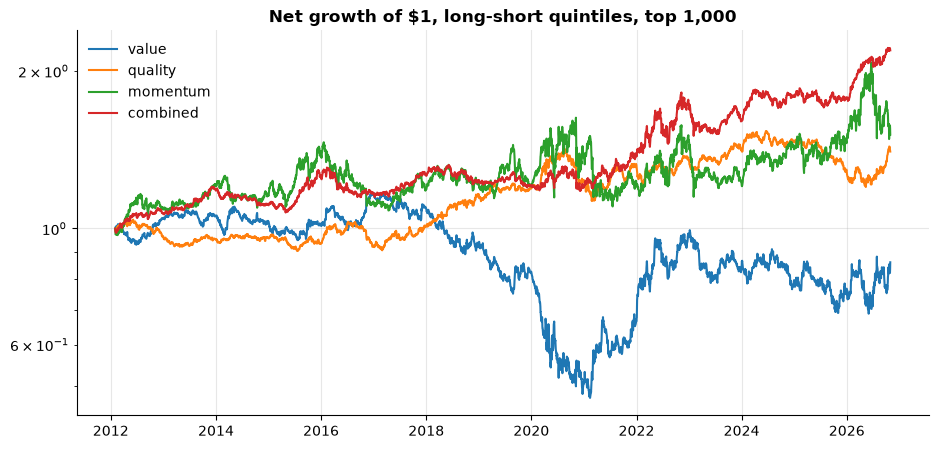

In [6]:
nets = pl.DataFrame({"date": strategies["value"].daily["date"]})
for n, b in strategies.items():
    nets = nets.join(b.daily.select("date", pl.col("net").alias(n)), on="date", how="left")
print("Correlation of daily net returns:")
print(nets.drop("date").corr().with_columns(pl.all().round(2)).with_columns(
    pl.Series("strategy", list(strategies))).select("strategy", *strategies))
fig, ax = plt.subplots(figsize=(11, 5))
for n, b in strategies.items():
    ax.plot(b.daily["date"], b.daily["nav"], label=n)
ax.set_yscale("log")
ax.set_title("Net growth of $1, long-short quintiles, top 1,000")
ax.legend()
plt.show()

Value alone lost money in large caps over this period (a 59% drawdown), quality and momentum
earned modest returns, and the combination beats all three: value and momentum are negatively
correlated (-0.50), so their losing streaks offset. Diversification across signals is the main
reason to combine them.

## 4 · Long and short legs, exposures

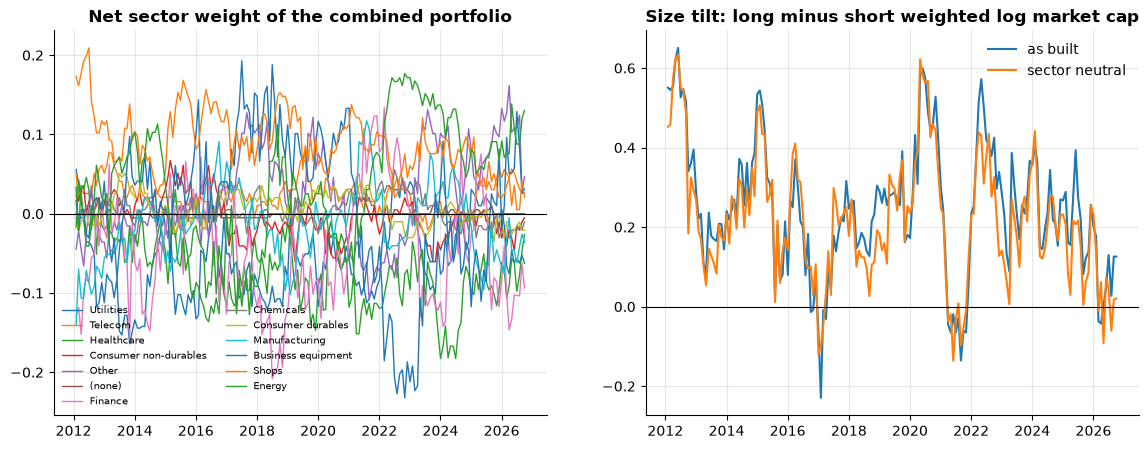

date,long_names,short_names,gross,net
date,u32,u32,f64,f64
2026-08-03,193,193,2.0,0.0
2026-09-01,192,192,2.0,-2.7756e-17
2026-10-01,192,192,2.0,-2.7756e-17


In [7]:
ex = bt.exposures()
sectors = [c for c in ex.columns if c not in ("date", "long_names", "short_names", "gross", "net", "size_tilt")]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for c in sectors:
    ax1.plot(ex["date"], ex[c], lw=1, label=c)
ax1.axhline(0, color="black", lw=0.8)
ax1.set_title("Net sector weight of the combined portfolio")
ax1.legend(fontsize=7, ncol=2)
sn = eng.run(quantile_weights(sig, "combined", q=0.2, sector_neutral=True)).exposures()
ax2.plot(ex["date"], ex["size_tilt"], label="as built")
ax2.plot(sn["date"], sn["size_tilt"], label="sector neutral")
ax2.axhline(0, color="black", lw=0.8)
ax2.set_title("Size tilt: long minus short weighted log market cap")
ax2.legend()
plt.show()
ex.select("date", "long_names", "short_names", "gross", "net").tail(3)

The portfolio carries sector bets of up to 20% of capital (long retailers, short healthcare
and technology at times), which sector-neutral weights remove. The size tilt is positive most
of the time: the long side holds larger companies than the short side, because profitable
companies with strong momentum tend to be big. That is why cap weighting does not hurt here.

## 5 · Capacity

With an AUM, each trade also pays square-root market impact: daily volatility x
sqrt(trade size / average daily dollar volume). A liquidity floor matters here: a few penny
ADRs reach the top 1,000 with market caps the data gets wrong (NCNA at $0.81 and $37,000 a day,
shown as a $6 billion company), and trading them would cost hundreds of basis points. These
runs drop names trading under $1 million a day.

In [8]:
rows = []
with timed("capacity"):
    for aum in [None, 1e7, 1e8, 1e9, 1e10]:
        b = eng.run(w, costs=CostModel(aum=aum), min_dollar_volume=1e6)
        rows.append({"aum_musd": aum / 1e6 if aum else 0.0, **{k: v for k, v in show(b, str(aum)).items()
                                                             if k in ("net_return", "net_sharpe", "cost_drag")}})
table(rows)

capacity: 128.01 s


aum_musd,net_return,net_sharpe,cost_drag
f64,f64,f64,f64
0.0,0.053,0.577,0.009
10.0,0.045,0.496,0.017
100.0,0.029,0.34,0.033
1000.0,-0.011,-0.058,0.073
10000.0,-0.087,-0.781,0.149


Impact adds under a point a year at $10 million, about 2.4 points at $100 million (net Sharpe
0.34), and from $1 billion the book loses money after costs. A monthly, equal-weighted book of
about 400 large and mid caps turning over 11 times a year is a small-capacity strategy: larger
money would need slower turnover, cap-tilted weights or a trade-cost-aware optimizer.

## 6 · Long-only

The 100 best names on the combined score, equal weighted, against SPY (beta and alpha come
from daily returns against SPY).

In [9]:
lo = eng.run(top_n_weights(sig, "combined", n=100))
spy = eng.market(lo.daily["date"].min(), lo.daily["date"].max())
spy_ann = float((1 + spy["ret"]).product()) ** (252 / spy.height) - 1
s = lo.summary().filter(pl.col("series") == "net").select("ann_return", "ann_vol", "sharpe", "max_drawdown",
                                                         "turnover_per_year", "cost_drag", "beta", "alpha")
print(f"SPY over the same period: {spy_ann:.1%} a year")
s.with_columns(pl.col(pl.Float64).round(3))

SPY over the same period: 14.5% a year


ann_return,ann_vol,sharpe,max_drawdown,turnover_per_year,cost_drag,beta,alpha
f64,f64,f64,f64,f64,f64,f64,f64
0.146,0.203,0.777,-0.417,6.331,0.003,1.098,-0.007


Long-only, the top 100 roughly matched SPY (14.6% against 14.5% a year) with a beta of 1.1
and no alpha. The long-short result comes mostly from the bottom of the ranking lagging, not
from the top beating the index.

## 7 · Caveats

- **One period, one universe**: 2012-2026, the 1,000 largest US-listed companies. The signals'
  directions come from older studies; several did little here.
- **Costs are models**: spreads from dollar volume, impact from a square-root law, a flat borrow
  rate with a hard-to-borrow surcharge. Real fills, borrow recalls and short squeezes are not
  in the data.
- **Delisting returns are a rule of thumb** (Shumway's -30% after a collapse); recoveries in
  bankruptcy are unknown here.
- **No risk model**: positions are equal weighted within quintiles; beta, sector and size
  exposures are reported, not controlled (sector-neutral weights are the exception). Risk
  models and optimization are planned for `borg-queen`.
- **Monthly signals at month-end closes**: daily signals work too (any dates in the weights),
  but the price signals' panel takes longer to build.